# Beyond the original JC/anti-JC CD protocol

**Hardware update: minimum vacuum swap time is 200 ns. The 260 ns CD below
requires approximately 35 ns swap coupling and is outside that limit.**
This notebook preserves the stronger-coupling comparison as an archive; its
260 ns result is not a device-feasible recommendation. The earlier 370 ns,
99.23% CD uses approximately 283 ns swap coupling and remains allowed.

This notebook compares actual higher-order product formulas and finite-pulse
corrections, rather than presenting XX−X−X as a new protocol. The targets are
CD(beta=1) and 8 dB conditional squeezing on all qubit g/e × Fock n=0..8
inputs. Relative phases and leakage count in the coherent process fidelity.

**New result:** an eight-pulse corrected symmetric product gives beta=1 CD in
**260 ns of programmed I/Q at 99.3713% fidelity**, with a fixed sideband phase.
A phase-cycle variant gives **99.4539% at the same duration**. These use much
stronger ideal JC coupling: about a 35 ns peak vacuum swap reference, versus
283 ns for the older 370 ns CD. This gain is an ideal-model prediction under
the assumed linear DAC-to-coupling relation, not a hardware calibration.

Every qubit pi envelope remains 30 ns. Fixed-phase JC stretches have 5 ns
amplitude ramps on each side. The ramps overlap the low-amplitude qubit edges;
the simultaneous Hamiltonian is propagated. I/Q changes are explicit samples.
No coupler model is used. Gate duration describes the envelopes, with both
channels referred to the same device time; buffer latency is not a gate cost.

Systematic pair removal gives **8 dB in 3.61 us at 99.0724%**, or 3.73 us at
99.2957%. The more aggressive 2.89 and 3.37 us attempts do not pass 99%.
The earlier 3.85 us construction gives 99.46%, illustrating the fidelity/time
tradeoff rather than a unique optimum.

In [1]:
# Locate code/ when this notebook is opened from notebooks/ or archive/.
from pathlib import Path as _Path
import sys as _sys
_project=next(p for p in [_Path.cwd(),*_Path.cwd().parents]
              if (p/'code/project_paths.py').is_file())
if str(_project/'code') not in _sys.path:
    _sys.path.insert(0,str(_project/'code'))
from project_paths import ROOT as PROJECT_ROOT, CODE, NOTEBOOKS


import os
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
import json, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import cd_trains as cd
import hardware_check as hw
from higher_order_cd import OUT, ROOT
from verify_higher_order_cd import make_model

FIGURES=OUT/'figures';FIGURES.mkdir(exist_ok=True)
def read(name):return json.loads((OUT/name).read_text())
def certificate(name):return json.loads((OUT/'verified'/(name+'.json')).read_text())
def finish(name):
    plt.savefig(FIGURES/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()
manifest=read('verified/manifest.json')
assert manifest['records']==64 and manifest['columns']==1152
print('Independent verification:',manifest['records'],'records;',manifest['columns'],
      'input columns;',manifest['independent_amplitudes'],'amplitudes;',manifest['accepted'],'above99%')
names=['overlap_strang_r4_s35','phasecycle_strang_r4_s35_a0.3','dcg_generator_weight0.005',
       'compressed_squeeze_n120','compressed_squeeze_n124']
display(pd.DataFrame([{k:r[k] for k in ['name','command_us','fidelity','ideal_device_fidelity','worst_basis_fidelity','qubit_frame_Rz']}
                      for r in map(certificate,names)]))


Independent verification: 64 records; 1152 input columns; 269568 amplitudes; 24 above99%


,name,command_us,fidelity,ideal_device_fidelity,worst_basis_fidelity,qubit_frame_Rz
0,overlap_strang_r4_s35,0.26,0.993713,0.993711,0.975818,0.000000
1,phasecycle_strang_r4_s35_a0.3,0.26,0.994539,0.994537,0.980185,0.000000
2,dcg_generator_weight0.005,0.26,0.993141,0.993139,0.973270,0.000000
3,compressed_squeeze_n120,3.61,0.990724,0.990691,0.961971,2.443874
4,compressed_squeeze_n124,3.73,0.992957,0.992937,0.970865,4.014364


## 1. What changing the Trotter approximation means

Choose the pump quadrature so that

$$A=H_{\rm JC}/g=\tfrac12(\sigma_xP-\sigma_yX),\qquad
B=\sigma_xA\sigma_x,\qquad A+B=\sigma_xP,$$

where $X=a+a^\dagger$ and $P=i(a^\dagger-a)$. Thus
$\exp[-i\beta(A+B)]=\mathrm{CD}(\beta)$.
The first-order and symmetric second-order approximations are

$$S_1(\delta)=e^{-i\delta A}e^{-i\delta B},\qquad
S_2(\delta)=e^{-i\delta A/2}e^{-i\delta B}e^{-i\delta A/2}.$$

A genuine fourth-order composition is

$$S_4(\delta)=S_2(p\delta)S_2(q\delta)S_2(p\delta),\quad
p=\frac1{2-2^{1/3}},\quad q=1-2p<0.$$

Negative intervals mean reversing the interaction sign, not negative physical
time. An isolated pi qubit conjugation turns JC into anti-JC. Adjacent equal
JC pieces are merged. Each A/B switch costs a 30 ns qubit pulse in the actual
sequence. Fourth order has larger coefficients and more switches, so a better
small-step scaling law need not give a shorter gate at beta=1 and n up to 8.

The following reference has **instantaneous qubit switches only**. It verifies
formal convergence and is not used as the hardware fidelity certificate.
See [splitting/composition review](https://arxiv.org/abs/0812.0377).

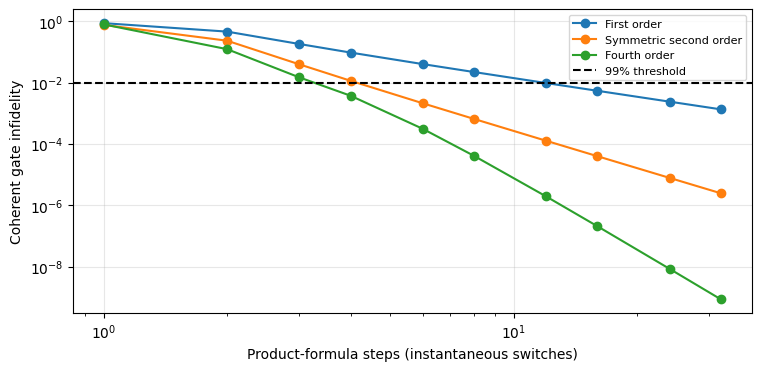

In [2]:

reference=pd.DataFrame(read('ideal_product_reference.json'))
assert len(reference)==30
fig,ax=plt.subplots(figsize=(7.5,3.6),constrained_layout=True)
for method,label in [('first','First order'),('strang','Symmetric second order'),('yoshida','Fourth order')]:
    r=reference[reference.method==method]
    ax.loglog(r.repeats,1-r.fidelity,'o-',label=label)
ax.axhline(.01,color='k',ls='--',label='99% threshold')
ax.set(xlabel='Product-formula steps (instantaneous switches)',ylabel='Coherent gate infidelity')
ax.grid(alpha=.3);ax.legend(fontsize=8);finish('formal_order')


## 2. Shorten the actual sequence, then correct its weights

For four symmetric steps, the chronological free-interaction word is

$$A/8,\ B/4,\ A/4,\ B/4,\ A/4,\ B/4,\ A/4,\ B/4,\ A/8.$$

Eight qubit pi pulses switch between its A and B pieces and return the qubit
frame. The pump is mostly off during each pi pulse. Its 5 ns fall and rise
overlap the first/last 5 ns of the adjacent qubit envelopes, saving 80 ns
relative to serial ramps and pulses. Full propagation includes that overlap.

The optimizer changes **nine JC amplitudes and eight qubit axes**, starting
from this symmetric formula. All elapsed intervals and qubit envelopes are
fixed. It corrects finite-step and finite-pulse error; the fitted result is
not asserted to retain fourth-order scaling. The simple accepted candidate
keeps all pump amplitudes positive, so its sideband phase is exactly fixed.

As a controlled comparison, a **phase-only** fit holds all nine JC magnitudes
and every interval fixed. It changes 99.3713% to only **99.3775%** at 260 ns.
This local result is a small improvement, not evidence of a universal limit.

The phase-cycle alternative additionally fits a transverse component of each
JC stretch, seeded with antisymmetric weights of zero leading sum. Each
stretch ramps to/from zero; phase changes occur between stretches. The
earlier continuous-pump attempts instead interpolate complex I/Q over 10 ns.

The strength plot uses the **largest fitted JC amplitude**, converted to
$t_{\rm swap,peak}=\pi/(2g_{\max})$. Each point is separately fitted; this is
not the calibration sensitivity of one fixed sequence. The nearly flat curves
are expected: changing g and inversely changing each JC duration preserves
its interaction area, and hence its ideal product-formula error. Keeping JC
mostly off during qubit rotations lets stronger coupling shorten those free
stretches. The plot at left shows the 90–100% region; worse fourth-order
attempts remain in the raw data.

The 260 ns recipe is verified for beta=1. The earlier signed-beta rule remains
the tested scaling family; arbitrary rescaling of this new corrected word is
not assumed to preserve its fidelity.

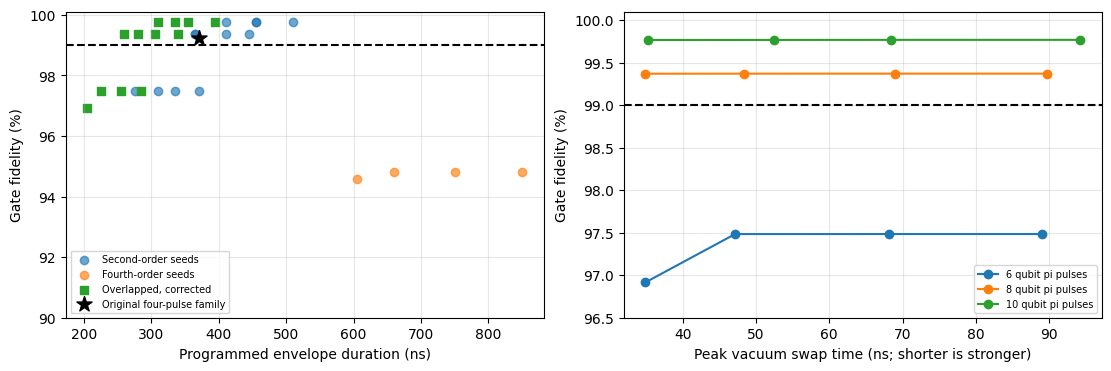

In [3]:

records=manifest['results']
fig,axes=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
for method,label in [('strang','Second-order seeds'),('yoshida','Fourth-order seeds')]:
    r=[x for x in records if x['name'].startswith('product_'+method)]
    axes[0].scatter([x['command_us']*1000 for x in r],[100*x['fidelity'] for x in r],label=label,alpha=.65)
overlap=[x for x in records if x['name'].startswith('overlap_')]
axes[0].scatter([x['command_us']*1000 for x in overlap],[100*x['fidelity'] for x in overlap],marker='s',label='Overlapped, corrected')
axes[0].scatter([370],[99.2277945],marker='*',s=130,c='k',label='Original four-pulse family')
axes[0].set(xlabel='Programmed envelope duration (ns)',ylabel='Gate fidelity (%)',ylim=(90,100.1))
for repeats in [3,4,5]:
    points=[]
    for x in overlap:
        r=read(x['source_record'])
        if r['job']['repeats']!=repeats:continue
        model=make_model(r);_,s,_,_,_=model.arrays(np.asarray(r['parameters']))
        points.append((1000*np.pi/(2*max(abs(s))),100*x['fidelity']))
    points.sort()
    axes[1].plot(*np.array(points).T,'o-',label=f'{2*repeats} qubit pi pulses')
axes[1].set(xlabel='Peak vacuum swap time (ns; shorter is stronger)',ylabel='Gate fidelity (%)',ylim=(96.5,100.1))
for ax in axes:ax.axhline(99,c='k',ls='--');ax.grid(alpha=.3);ax.legend(fontsize=7)
finish('actual_duration_and_strength')


## 3. Literal pulse prescription and device I/Q

The fixed-phase 260 ns candidate is shown below. The pulse table gives the
physical qubit DAC axes; the JC table gives each programmed interval and its
coupling. The qubit and sideband share one timeline. Each JC interval contains
its 5 ns turn-on and 5 ns turn-off. Every qubit envelope is a full pi, 30 ns.

The plot overlays programmed samples and their modeled RFDC shapes after
removing the **common group delay** from the display. A common delay cannot
change coherent fidelity. The complete filtered shapes are still used for
propagation. Magnitude means $|I+iQ|=\sqrt{I^2+Q^2}$ for each physical channel.

Exact physical I/Q words and qubit timing are saved beside the
[certificate](../../runs/higher_order_cd/verified/overlap_strang_r4_s35.json) and
[qubit pulse CSV](../../runs/higher_order_cd/verified/overlap_strang_r4_s35_qubit_sequence.csv).

,pulse,start_ns,duration_ns,qubit_DAC_deg
0,1,5.00,30,0.01013
1,2,36.25,30,0.01869
2,3,67.50,30,180.01597
3,4,98.75,30,180.00155
4,5,130.00,30,359.98520
5,6,161.25,30,359.98155
6,7,192.50,30,179.98918
7,8,223.75,30,179.99749


,section,frame,start_ns,duration_ns,g_rad_per_us,area_rad,pump_DAC_deg
0,1,A,0.00,10.00,23.559418,0.117797,270
1,2,B,30.00,11.25,40.152210,0.250951,270
2,3,A,61.25,11.25,45.000000,0.281250,270
3,4,B,92.50,11.25,43.799077,0.273744,270
4,5,A,123.75,11.25,42.050915,0.262818,270
5,6,B,155.00,11.25,42.070703,0.262942,270
6,7,A,186.25,11.25,41.863046,0.261644,270
7,8,B,217.50,11.25,36.194977,0.226219,270
8,9,A,248.75,10.00,20.674256,0.103371,270


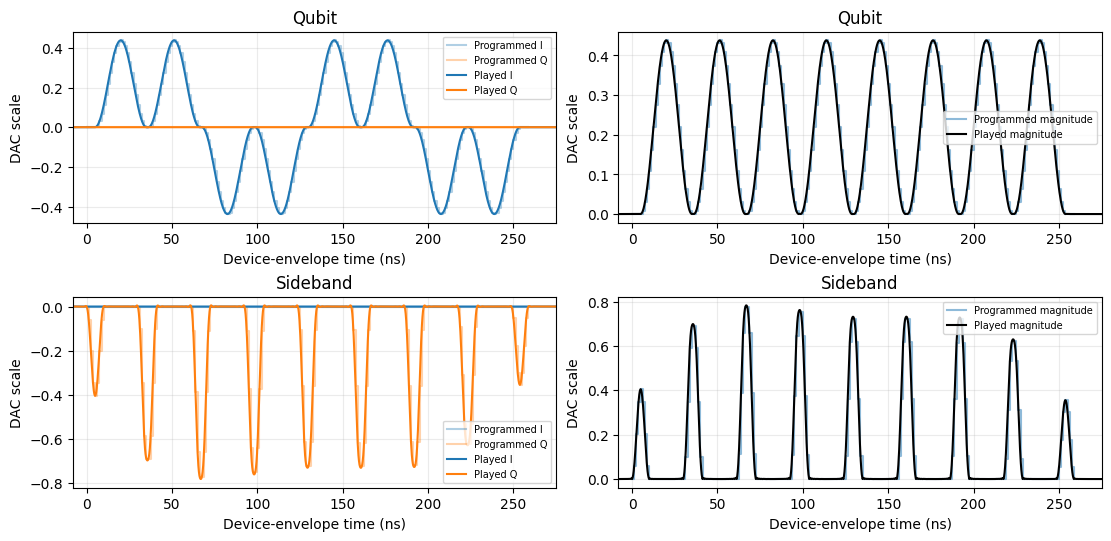

In [4]:

best=read('overlap_strang_r4_s35.json');model=make_model(best)
p=np.asarray(best['parameters']);q,s,qf,sf,words=model.arrays(p)
pulses=[]
for j in range(model.cells):
    indices=np.flatnonzero(model.qcell==j)
    pulses.append(dict(pulse=j+1,start_ns=indices[0]*cd.DT*1000,duration_ns=30,
                       qubit_DAC_deg=float(-np.degrees(p[j])%360)))
display(pd.DataFrame(pulses).round(5))
sections=[]
for j in range(model.section_count):
    column=model.W.getcol(j).toarray()[:,0];indices=np.flatnonzero(column)
    start=max(0,indices[0]-1);end=indices[-1]+1
    sections.append(dict(section=j+1,frame=model.coefficients[j][0],start_ns=start*cd.DT*1000,
                         duration_ns=(end-start)*cd.DT*1000,g_rad_per_us=p[model.cells+j],
                         area_rad=p[model.cells+j]*column.sum()*cd.DT,pump_DAC_deg=270))
display(pd.DataFrame(sections).round(7))
pd.DataFrame(sections).to_csv(OUT/'verified/overlap_strang_r4_s35_JC_sequence.csv',index=False)
delay=np.argmax(abs(hw.rfdc_interpolate(np.array([1.]))))*cd.DT/8
qs,ss=hw.dac_scales(.6)
played=[qf.conj()/(np.pi/cd.PI_TIME)*qs,sf/(np.pi/(2*.6))*ss]
fig,axes=plt.subplots(2,2,figsize=(11,5.3),constrained_layout=True)
for row,(channel,key,filtered) in enumerate(zip(['Qubit','Sideband'],['qubit','sideband'],played)):
    raw=hw.sample_to_complex(words[key]);t=np.arange(len(raw))*cd.DT*1000
    tf=(np.arange(len(filtered))*cd.DT/8-delay)*1000
    axes[row,0].step(t,raw.real,where='post',alpha=.35,c='C0',label='Programmed I')
    axes[row,0].step(t,raw.imag,where='post',alpha=.35,c='C1',label='Programmed Q')
    axes[row,0].plot(tf,filtered.real,c='C0',label='Played I')
    axes[row,0].plot(tf,filtered.imag,c='C1',label='Played Q')
    axes[row,1].step(t,abs(raw),where='post',alpha=.5,label='Programmed magnitude')
    axes[row,1].plot(tf,abs(filtered),'k',label='Played magnitude')
    for ax in axes[row]:
        ax.set(title=channel,xlabel='Device-envelope time (ns)',ylabel='DAC scale',xlim=(-8,275))
        ax.grid(alpha=.25);ax.legend(fontsize=7)
finish('device_IQ_and_magnitude')


## 4. Phase cycling and a dynamically corrected gate objective

A true dynamically corrected gate cancels a specified leading error generator.
High nominal fidelity alone does not establish that cancellation. Here the
additional ensemble fit minimizes average infidelity at qubit gains 0.97, 1
and 1.03, while keeping the same 260 ns duration. That alone did not improve
the leading sensitivity. A separate, direct generator penalty minimizes

$$J=1-F_{\rm nominal}+\lambda\,
\frac{1-|\operatorname{Tr}[V(-\epsilon)^\dagger V(+\epsilon)]/18|^2}{4\epsilon^2},
\qquad \epsilon=0.01.$$

The second term tends to the squared leading projective error-generator norm.
Both control-dependences in that term are differentiated, and its gradient is
checked against finite differences. With weight 0.005, the corrected candidate
retains **99.3141%** fidelity and lowers the gain-derivative norm from **1.0251
to 0.8977** at the same duration. Weight 0.02 lowers it further to **0.6948**,
but nominal fidelity drops to **98.9866%**, failing the requested threshold.

For actual output columns $V(\epsilon)$ with qubit gain $1+\epsilon$, the
reported sensitivity is the Frobenius norm of

$$D=\left.\frac{\partial V}{\partial\epsilon}\right|_0
-i\gamma V(0),\qquad
\gamma=\operatorname{Im}\operatorname{Tr}[V(0)^\dagger\partial_\epsilon V]/18.$$

Only an irrelevant global phase is removed. Nonzero D means first-order
sensitivity remains: this is a robust-fit candidate, not a claimed exact DCG.
The finite difference is checked at two step sizes. This distinction follows
the [DCG synthesis formulation](https://arxiv.org/html/1205.0217v2).

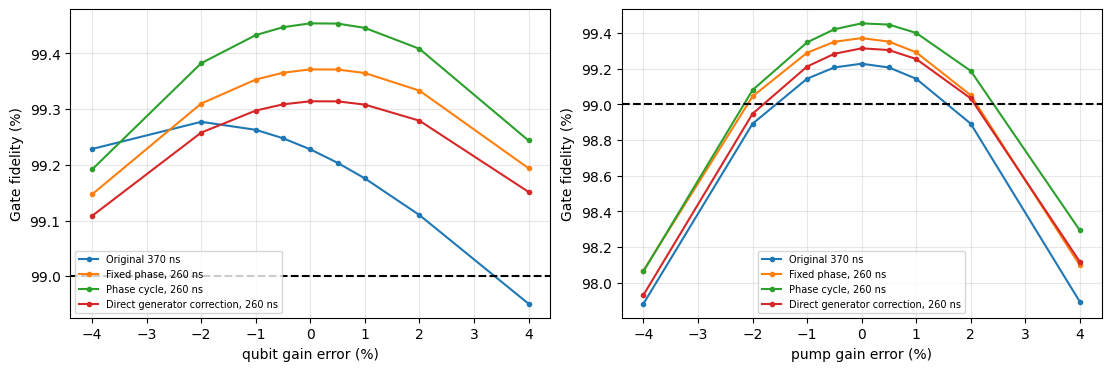

,name,qubit_gain_derivative_norm,derivative_step_change
0,baseline,1.109584,0.000006
1,overlap_strang_r4_s35,1.025090,0.000009
2,phasecycle_strang_r4_s35_a0.3,1.091936,0.000008
3,dcg_strang_r4_a0.2,1.038700,0.000009
4,dcg_generator_weight0.005,0.897673,0.000008
5,dcg_generator_weight0.02,0.694837,0.000005


Sensitivity comparisons: 108 points; 1944 columns; 373248 cutoff comparison amplitudes


In [5]:

sensitivity=read('sensitivity.json');data=pd.DataFrame(sensitivity['curves'])
labels={'baseline':'Original 370 ns','overlap_strang_r4_s35':'Fixed phase, 260 ns',
        'phasecycle_strang_r4_s35_a0.3':'Phase cycle, 260 ns','dcg_generator_weight0.005':'Direct generator correction, 260 ns'}
fig,axes=plt.subplots(1,2,figsize=(11,3.6),constrained_layout=True)
for ax,error in zip(axes,['qubit_gain','pump_gain']):
    for name,label in labels.items():
        r=data[(data.name==name)&(data.error==error)]
        ax.plot(100*(r.gain-1),100*r.fidelity,'o-',ms=3,label=label)
    ax.axhline(99,c='k',ls='--');ax.set(xlabel=error.replace('_',' ')+' error (%)',ylabel='Gate fidelity (%)')
    ax.grid(alpha=.3);ax.legend(fontsize=7)
finish('phase_cycle_and_DCG_sensitivity')
display(pd.DataFrame(sensitivity['derivatives']))
print('Sensitivity comparisons:',sensitivity['points'],'points;',sensitivity['columns'],'columns;',
      sensitivity['cutoff_comparison_amplitudes'],'cutoff comparison amplitudes')


## 5. Conditional squeezing: shorter is not accepted until it passes

The target remains fixed at

$$S_z(r)=\exp[\tfrac r2\sigma_z(a^2-a^{\dagger2})],\qquad r=8\ln(10)/20.$$

Three 96-pulse fits continue the earlier short commutator-based candidates,
now allowing a complex JC weight in each cell. The I/Q interpolates smoothly
for 10 ns between cells. Their free variables are 96 qubit axes plus 96 complex
JC weights; their local search budgets are saved. They reach at most 98.45%
after cutoff convergence, so the 2.89 us candidates are rejected.

A separate, systematic continuation removes the least damaging adjacent
qubit-pulse pair from the accepted 128-pulse gate, then corrects the phases.
The starting coupling scales as $g\propto N^{-1/2}$, motivated by the leading
commutator area $Ng^2$. The 120-pulse intermediate reaches **99.0724% in
3.61 us**, and 124 pulses gives **99.2957% in 3.73 us** after actual I/Q
corrections. Eight pair removals leave 112 pulses; this 3.37 us candidate
reaches only 98.59% and is rejected. These final fits optimize qubit and pump
phases and one common g; the new 120-pulse target has not been changed.

The [complete 120-pulse table](../../runs/higher_order_cd/verified/compressed_squeeze_n120_sequence.csv)
lists the physical qubit and pump phases, timing and common coupling. Apply
the single final qubit Rz printed in the first results table **after the whole
train**. Its tracked frame is included in the reported coherent fidelity.

These local failures are not a speed-limit proof. Ordinary commutator echoes
and formal higher order can have large coefficients at 8 dB and n up to 8;
their complete gate fidelity must be checked rather than inferred from order.

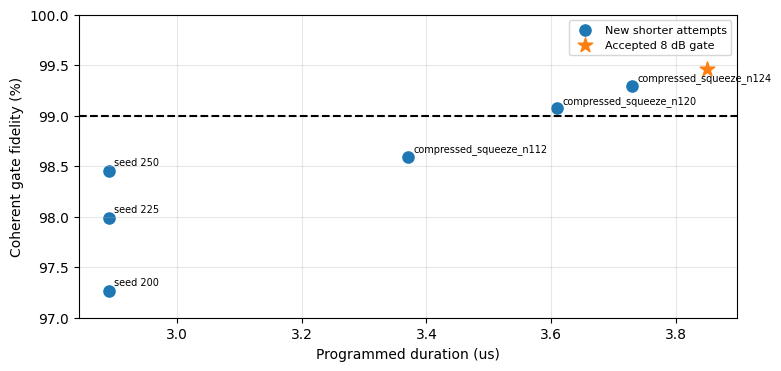

,name,fidelity,command_us,levels,independent_max_difference
0,corrected_squeeze_n96_seed200,0.972635,2.89,320,6.393188e-15
1,corrected_squeeze_n96_seed225,0.979908,2.89,320,4.361302e-15
2,corrected_squeeze_n96_seed250,0.984516,2.89,320,4.499744e-15
3,compressed_squeeze_n120,0.990724,3.61,320,5.029277e-15
4,compressed_squeeze_n124,0.992957,3.73,320,4.704468e-15
5,compressed_squeeze_n112,0.985922,3.37,320,5.667343e-15


In [6]:

squeezes=[r for r in records if r['gate']=='squeeze']
previous=json.loads((ROOT/'runs/constant_pump_gaussian/verified/strength_squeeze_swap300.json').read_text())
fig,ax=plt.subplots(figsize=(7.7,3.6),constrained_layout=True)
ax.scatter([r['command_us'] for r in squeezes],[100*r['fidelity'] for r in squeezes],s=65,label='New shorter attempts')
ax.scatter([previous['command_us']],[100*previous['fidelity']],s=120,marker='*',label='Accepted 8 dB gate')
for r in squeezes:ax.annotate(r['name'].replace('corrected_squeeze_n96_seed','seed '),
        (r['command_us'],100*r['fidelity']),xytext=(4,4),textcoords='offset points',fontsize=7)
ax.axhline(99,c='k',ls='--');ax.set(xlabel='Programmed duration (us)',ylabel='Coherent gate fidelity (%)',ylim=(97,100))
ax.grid(alpha=.3);ax.legend(fontsize=8);finish('squeeze_shortening_checks')
display(pd.DataFrame([{k:r[k] for k in ['name','fidelity','command_us','levels','independent_max_difference']} for r in squeezes]))


## 6. Fresh simulation and the limits of this comparison

The following cell runs the accepted CD again with the independent order-16
propagator at a larger oscillator cutoff, compares every complex output
amplitude and recomputes fidelity. No input or leaked output is renormalized.

The finite searches cover first/second/fourth-order seeds, signed interaction
weights, qubit-axis reflection, transverse phase cycles and a gain-error
objective. They do not exhaust all continuous waveforms. Every plotted fitted
candidate has separate target/output cutoff checks, including failures.
The ideal two-level JC model excludes dissipation and coupler corrections.

FRESH INDEPENDENT CD:18columns; 4608 amplitudes;maxdifference 2.8757454971911127e-25 F 0.9937127840681839
Device I/Q duration 260.0 ns; fixed sideband phase; all pi envelopes30ns


FRESH INDEPENDENT SQUEEZE:2boundaryinputs; 1536 amplitudes;maxdifference 2.2903921347163597e-15


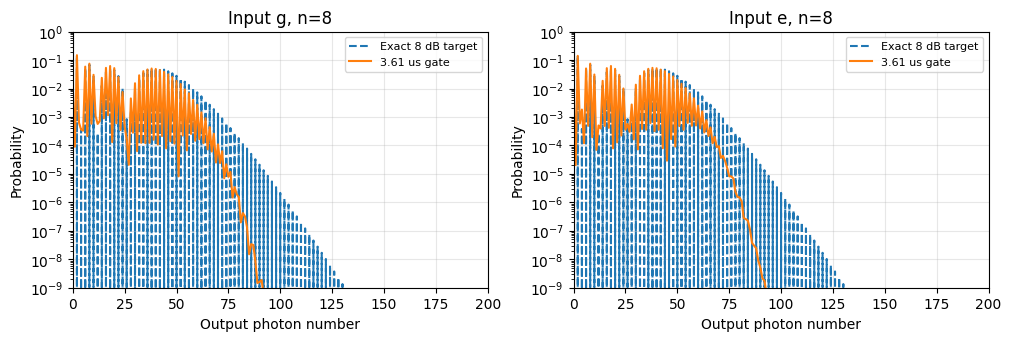

In [7]:

saved=certificate('overlap_strang_r4_s35')
columns=np.load(OUT/'verified/overlap_strang_r4_s35_columns.npz')
space=cd.Space(128,9);initial=np.eye(256,dtype=complex)[:,space.inputs]
replay=hw.propagate(qf,sf,initial,cd.DT/8,order=16)
target=cd.target_columns(space,'cd',1.)
embedded=np.zeros_like(replay);embedded[:len(columns['output'])]=columns['output']
error=float(np.max(abs(replay-embedded)))
fidelity=float(abs(np.vdot(target,replay)/18)**2)
assert replay.shape==(256,18) and error<1e-10 and fidelity>.99
digest=hashlib.sha256(words['qubit'].tobytes()+words['sideband'].tobytes()).hexdigest()
assert digest==saved['word_sha256']
print('FRESH INDEPENDENT CD:18columns;',replay.size,'amplitudes;maxdifference',error,'F',fidelity)
print('Device I/Q duration',saved['command_us']*1000,'ns; fixed sideband phase; all pi envelopes30ns')

# Fresh independent replay of both boundary inputs for the NEW squeezing gate.
# Its full 18-column process comparison is in the counted certificate above.
sq=read('compressed_squeeze_n120.json');sqmodel=make_model(sq)
_,_,qSq,sSq,_=sqmodel.arrays(np.asarray(sq['parameters']))
sqcert=certificate('compressed_squeeze_n120')
sqspace=cd.Space(384,9)
sqinitial=np.eye(768,dtype=complex)[:,[16,17]]  # explicit g8 and e8
sqoutput=hw.propagate(qSq,sSq,sqinitial,cd.DT/8,order=16)
sqoutput*=np.exp(-1j*sqcert['qubit_frame_Rz']*sqspace.z/2)[:,None]
sqtarget=cd.target_columns(sqspace,'squeeze',cd.R_8DB)[:,[8,17]]
sqstored=np.load(OUT/'verified/compressed_squeeze_n120_columns.npz')['output'][:,[8,17]]
sqembedded=np.zeros_like(sqoutput);sqembedded[:len(sqstored)]=sqstored
sqerror=float(np.max(abs(sqoutput-sqembedded)))
assert sqoutput.shape==(768,2) and sqerror<1e-10
print('FRESH INDEPENDENT SQUEEZE:2boundaryinputs;',sqoutput.size,'amplitudes;maxdifference',sqerror)
fig,axes=plt.subplots(1,2,figsize=(10,3.3),constrained_layout=True)
for col,ax in enumerate(axes):
    exact=(abs(sqtarget[:,col])**2).reshape(-1,2).sum(axis=1)
    actual=(abs(sqoutput[:,col])**2).reshape(-1,2).sum(axis=1)
    ax.semilogy(exact,'--',label='Exact 8 dB target')
    ax.semilogy(actual,label='3.61 us gate')
    ax.set(title=['Input g, n=8','Input e, n=8'][col],xlabel='Output photon number',ylabel='Probability',
           xlim=(0,200),ylim=(1e-9,1))
    ax.grid(alpha=.3);ax.legend(fontsize=8)
finish('fresh_squeeze_boundary_inputs')
